# Game Outcome Model

Home win probability and point margin for every regular-season game, using only information available before tip-off.

| Feature family | Definition |
|---|---|
| Home court | 1 for a home game, 0 at a neutral site (2020 bubble, NBA Cup semifinals, Mexico City and Europe) |
| Elo | Pre-game Elo difference with a margin-of-victory multiplier (FiveThirtyEight's NBA formula); K = 20, home edge 85 points, 60% carried over between seasons, tuned on 2001-02 to 2012-13 |
| Team ratings | Offensive, defensive and net rating, pace and the Four Factors for and against, season to date, blended with 15 games of last season's rates (regressed a third of the way to the league average) |
| Recent form | Net rating over the previous 10 games |
| Schedule & travel | Rest days (capped at 4), back-to-backs, games in the previous 4 days, distance travelled since the previous game, time zones crossed (positive = east) and arena altitude |
| Roster talent | Minutes-weighted projected BPM of the available players / 48 (a net-rating scale). Players get minutes in order of expected minutes until 240 are used; leftover minutes go to a replacement-level player (BPM -2) |
| Availability | Talent of the full roster minus talent of the available players, and whether the team's most valuable player is out |
| Roster turnover | Share of the franchise's minutes last season played by players on the current roster |

**Player values** are made before each season with no later data: the walk-forward season projection ([07_season_projections](07_season_projections.ipynb)) for veterans, the college model ([06_rookie_projections](06_rookie_projections.ipynb), leave-one-class-out) for rookies from college, and a draft-slot model for other drafted rookies. Expected minutes blend projected minutes per game with minutes played so far that season (10 games of projection). A player counts as available if they played or were dressed but unused; any other listed reason ('Inactive', 'Did Not Dress', 'Not With Team', 'Suspended') counts as absent. In live use, the official injury report takes this role.

**Evaluation:** walk-forward. Each season from 2015-16 to 2025-26 is predicted by models fit on every season from 2013-14 up to the one before (roster features start in 2013-14). Margin models give a win probability through a normal distribution with the training residual SD.

Source: Basketball-Reference (team game logs 2000-01 to 2025-26, player game logs 2013-14 to 2025-26).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.teams.games import (ALL_FEATURES, FAMILIES, MODELS, calibration,
                                       compare_feature_sets, family_importance, game_dataset,
                                       margin_residuals, scores, walk_forward)
from nba_analytics.teams.games_plots import (plot_calibration, plot_feature_sets,
                                             plot_home_court, plot_importance,
                                             plot_scores_by_season, plot_situations,
                                             plot_talent_missing)
from nba_analytics.teams.net_rating import game_logs
from nba_analytics.teams.games import ELO_PARAMS, game_features

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

FIRST_TEST, LAST_TEST = 2016, 2026
games = game_dataset(2014, 2026)
history = game_features(game_logs(range(2001, 2027)), ELO_PARAMS)

## Home-court advantage

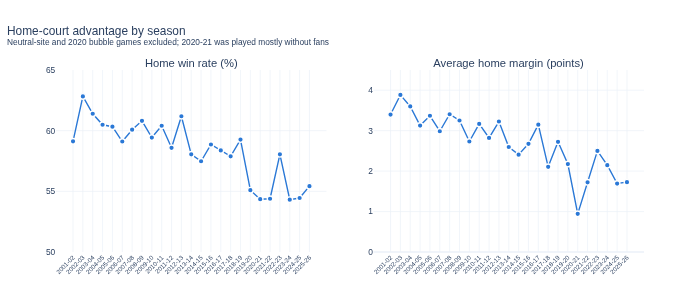

In [2]:
plot_home_court(history[history["season"] >= 2002]).show()

## Models

In [3]:
preds = walk_forward(games, ALL_FEATURES, FIRST_TEST, LAST_TEST)
preds["Elo only"] = games.set_index("game_id").loc[preds["game_id"], "elo_prob"].to_numpy()
preds["Home team always"] = preds.groupby("season")["home_win"].transform(
    lambda s: 0 * s + games.loc[games["season"] < s.name, "home_win"].mean())
prob_cols = [*MODELS, "Elo only", "Home team always"]
scores(preds, prob_cols).round(4)

,model,n,log_loss,brier,accuracy
0,Logistic regression,13209,0.6048,0.2088,0.6685
1,Boosted trees,13209,0.6077,0.2099,0.6698
2,Ridge (margin),13209,0.6043,0.2086,0.6709
3,Boosted trees (margin),13209,0.6065,0.2096,0.6692
4,Elo only,13209,0.6225,0.2166,0.6536
5,Home team always,13209,0.6850,0.2459,0.5644


In [4]:
margin = preds[[c for c in preds if c.endswith(" pred")]].sub(preds["margin"], axis=0)
pd.DataFrame({"MAE": margin.abs().mean(), "RMSE": (margin ** 2).mean() ** 0.5}).round(2)

,MAE,RMSE
Ridge (margin) pred,10.27,13.15
Boosted trees (margin) pred,10.31,13.21


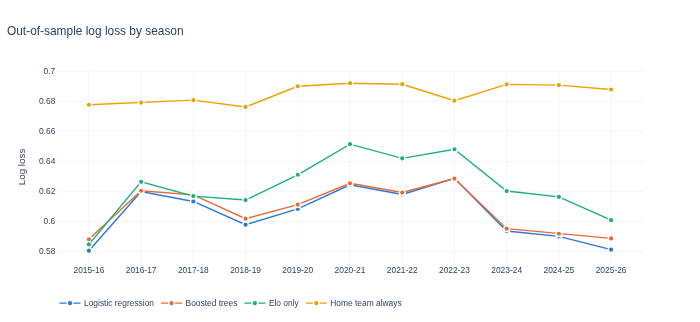

In [5]:
by_season = scores(preds, prob_cols, by_season=True)
plot_scores_by_season(by_season, ["Logistic regression", "Boosted trees", "Elo only",
                                  "Home team always"]).show()

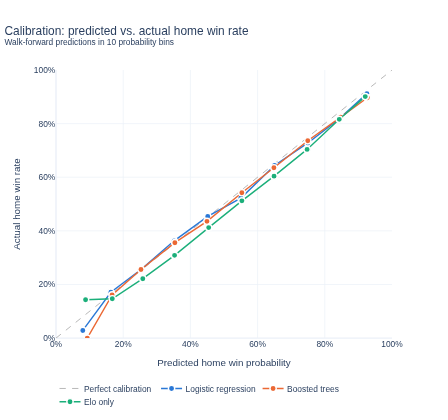

In [6]:
plot_calibration({m: calibration(preds, m) for m in ["Logistic regression",
                                                     "Boosted trees", "Elo only"]}).show()

## Feature families

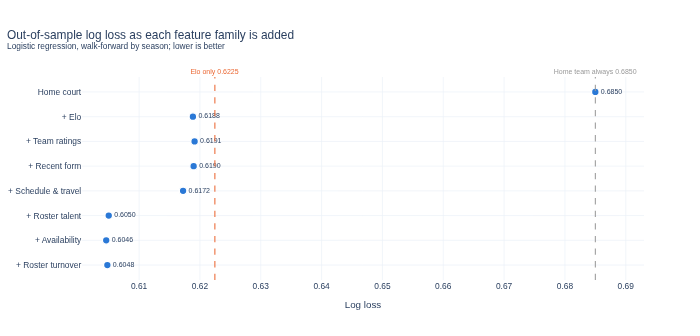

In [7]:
comp = compare_feature_sets(games, FIRST_TEST, LAST_TEST)
base = scores(preds, ["Home team always", "Elo only"]).set_index("model")["log_loss"]
plot_feature_sets(comp, base.to_dict()).show()

In [8]:
comp.round(4)

,model,n,log_loss,brier,accuracy,features
0,Logistic regression,13209,0.6850,0.2459,0.5644,Home court
1,Logistic regression,13209,0.6188,0.2151,0.6540,+ Elo
2,Logistic regression,13209,0.6191,0.2152,0.6558,+ Team ratings
3,Logistic regression,13209,0.6190,0.2151,0.6558,+ Recent form
4,Logistic regression,13209,0.6172,0.2144,0.6569,+ Schedule & travel
5,Logistic regression,13209,0.6050,0.2089,0.6700,+ Roster talent
6,Logistic regression,13209,0.6046,0.2087,0.6689,+ Availability
7,Logistic regression,13209,0.6048,0.2088,0.6685,+ Roster turnover


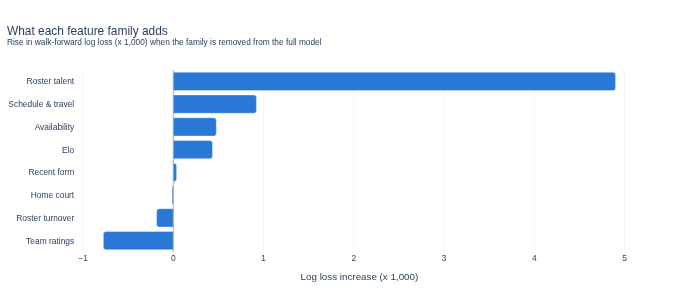

In [9]:
imp = family_importance(games, FIRST_TEST, LAST_TEST)
plot_importance(imp).show()

## Game situations

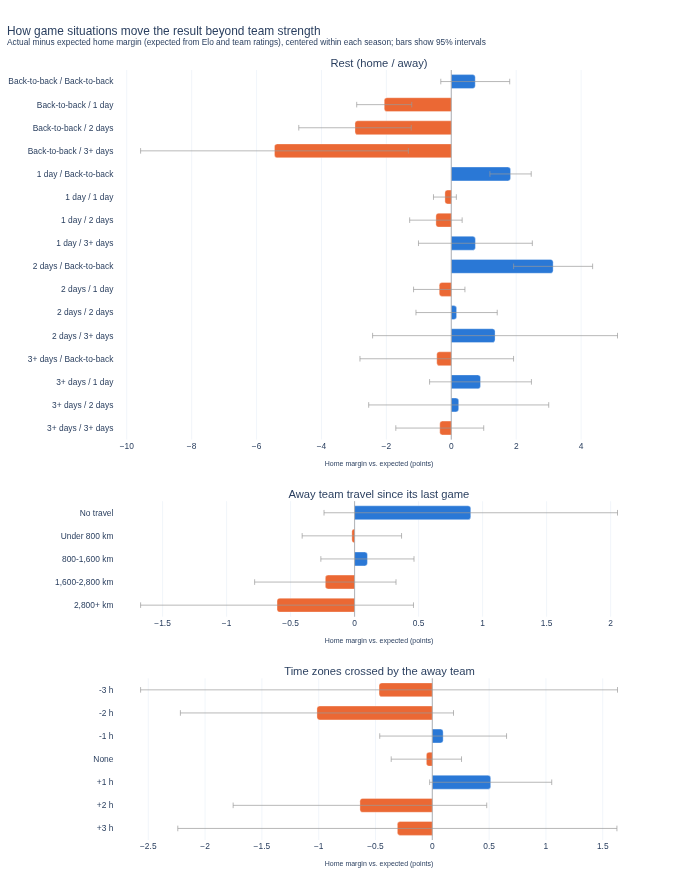

In [10]:
res = margin_residuals(games, FIRST_TEST, LAST_TEST)
rest = {0: "Back-to-back", 1: "1 day", 2: "2 days", 3: "3+ days", 4: "3+ days"}
order = [f"{h} / {a}" for h in dict.fromkeys(rest.values()) for a in dict.fromkeys(rest.values())]
zones = ["-3 h", "-2 h", "-1 h", "None", "+1 h", "+2 h", "+3 h"]
groups = {
    "Rest (home / away)": pd.Categorical(
        res["home_rest_days"].map(rest) + " / " + res["away_rest_days"].map(rest), order),
    "Away team travel since its last game": pd.cut(
        res["away_travel_km"], [-1, 1, 800, 1600, 2800, 10000],
        labels=["No travel", "Under 800 km", "800-1,600 km", "1,600-2,800 km", "2,800+ km"]),
    "Time zones crossed by the away team": pd.Categorical(res["away_tz_shift"].clip(-3, 3).map(
        lambda h: f"{h:+.0f} h" if h else "None"), zones),
}
plot_situations(res, groups).show()

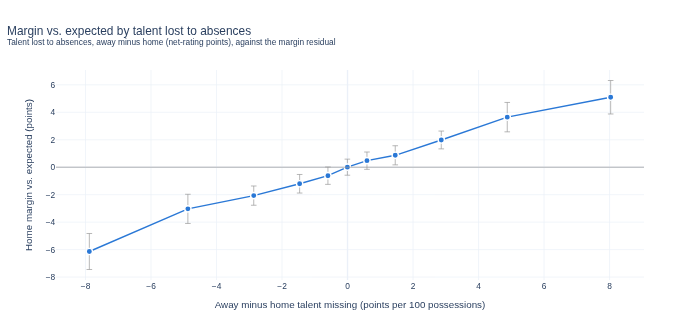

In [11]:
plot_talent_missing(res, [-30, -6, -4, -2, -1, -0.25, 0.25, 1, 2, 4, 6, 30]).show()